# Homework 2 — DSCI 552


**Student:** Yuxin Yang 1505451394

**Late-Day Declaration:** I would like to use one of my three allotted late days for this Homework.


<a id="data"></a>
## 1(a). Download and load the data
Source: [UCI Combined Cycle Power Plant](https://archive.ics.uci.edu/dataset/294/combined+cycle+power+plant), Tüfekci & Kaya (2014), [DOI: 10.24432/C5002N](https://doi.org/10.24432/C5002N), CC BY 4.0.

The five worksheets are permutations of the same observations, so concatenating them would replicate the sample. The workbook names temperature **AT** (the assignment's T) and output **PE** (the assignment's EP). These original names are retained throughout.

In [1]:
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile
from io import BytesIO
import pandas as pd
from urllib.error import URLError

DATA_URL = (
    "https://archive.ics.uci.edu/static/public/294/"
    "combined+cycle+power+plant.zip"
)

# Created relative to the notebook's working directory.
data_dir = Path("data")
data_dir.mkdir(parents=True, exist_ok=True)
excel_path = data_dir / "Folds5x2_pp.xlsx"

# Download only if the workbook is not already available.
if not excel_path.exists():
    try:
        with urlopen(DATA_URL, timeout=60) as response:
            zip_data = response.read()
    except (URLError, TimeoutError) as exc:
        raise RuntimeError(
            "Download failed. Check your internet connection and try again. "
            "Alternatively, place Folds5x2_pp.xlsx in the data folder."
        ) from exc

    with ZipFile(BytesIO(zip_data)) as archive:
        workbook = next(
            name for name in archive.namelist()
            if name.endswith("Folds5x2_pp.xlsx")
        )
        excel_path.write_bytes(archive.read(workbook))

# The five sheets are shuffled versions of the same dataset.
df = pd.read_excel(excel_path, sheet_name="Sheet1", engine="openpyxl")

print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns.")
display(df.head())

Loaded 9,568 rows and 5 columns.


,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


## 1(b). Explore the data
### (i) Rows and columns
The dataset contains **9,568 rows and 5 columns**. 
Each row represents an hourly average observation collected from a combined cycle power plant operating at full load during 2006–2011. 
The columns contain four predictors and one response variable.

| Column | Meaning | Unit | Role |
|---|---|---|---|
| AT | Ambient temperature | °C | Predictor |
| V | Exhaust vacuum | cm Hg | Predictor |
| AP | Ambient pressure | millibar | Predictor |
| RH | Relative humidity | % | Predictor |
| PE | Net hourly electrical output | MW | Response |


### (ii) Pairwise scatterplots

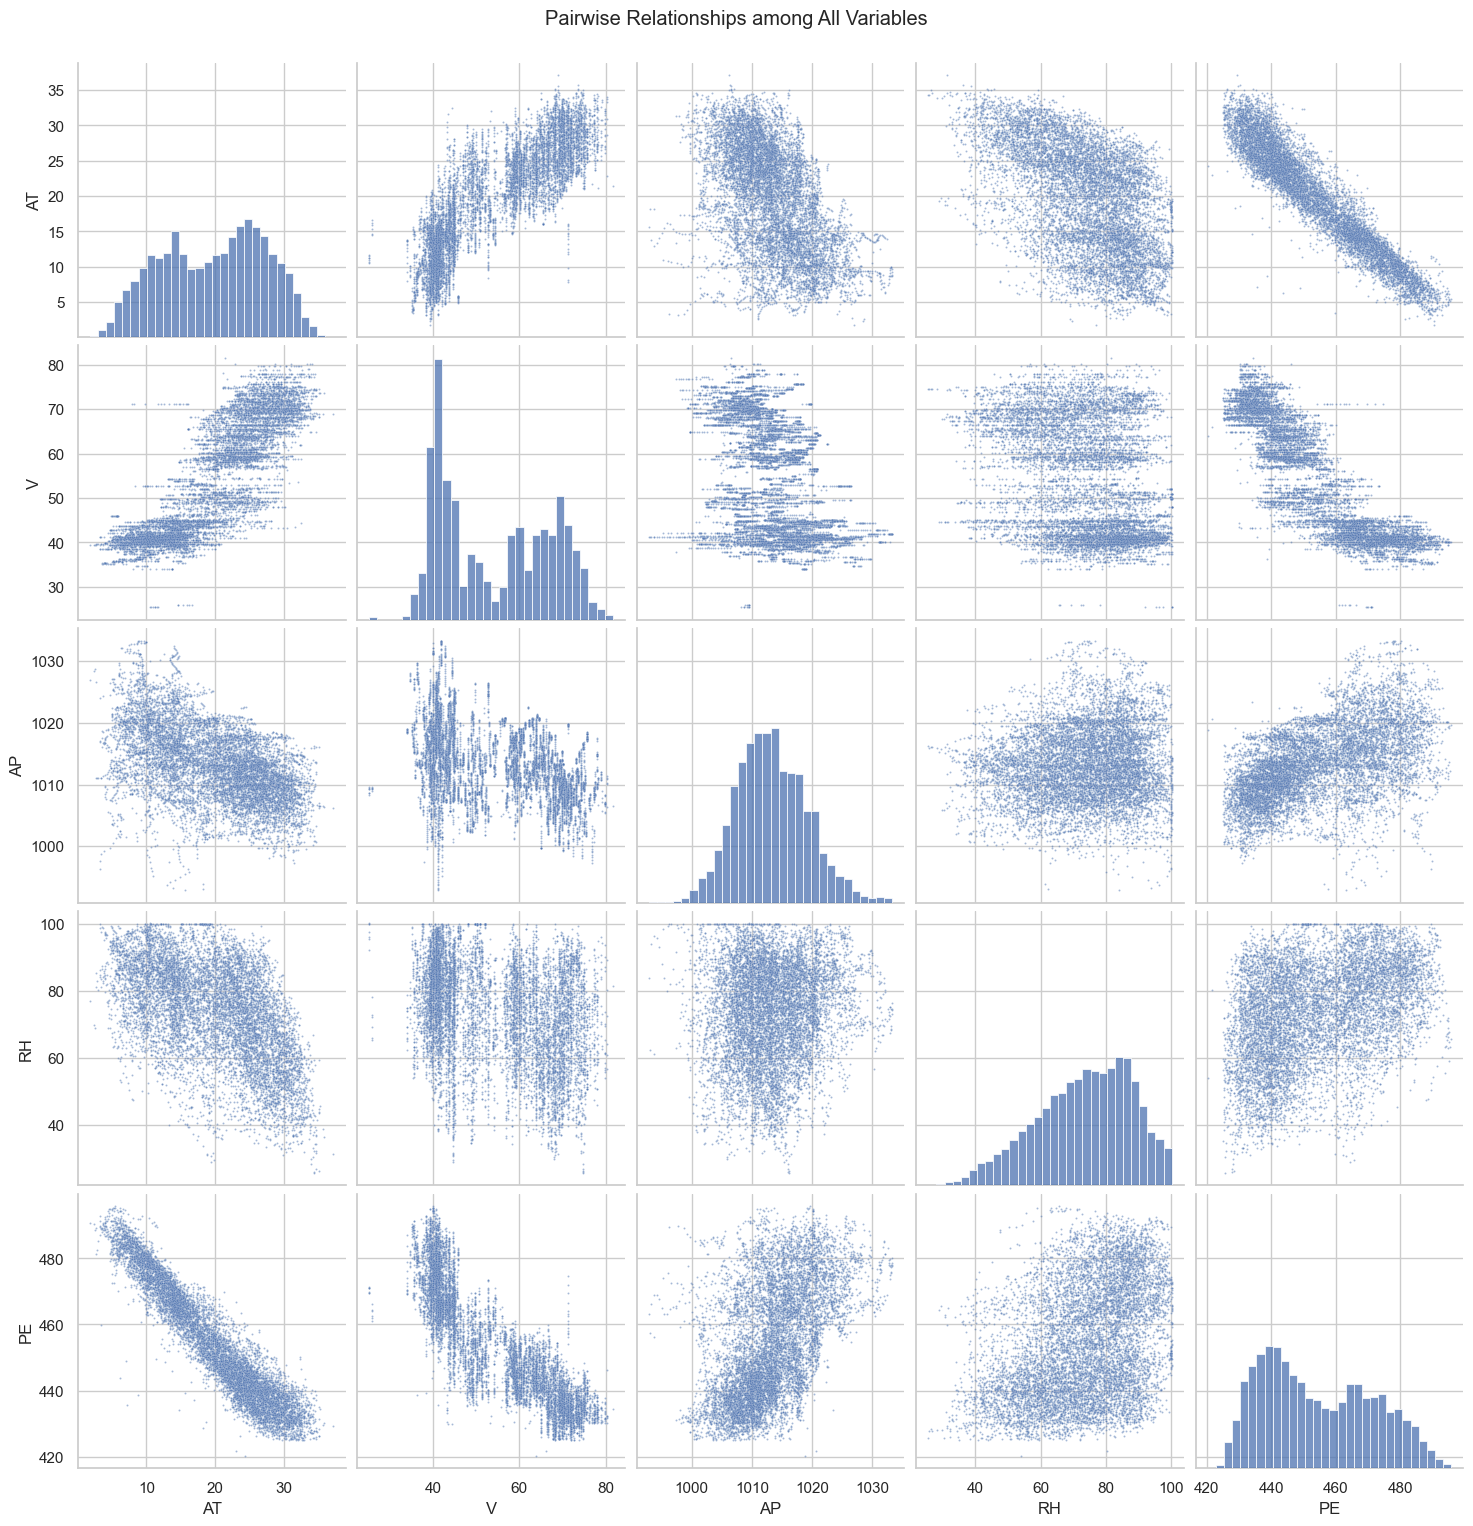

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

g = sns.pairplot(
    df,
    diag_kind="hist",
    height=3,
    plot_kws={"s": 2, "alpha": 0.5},
    diag_kws={"bins": 30}
)

g.figure.suptitle("Pairwise Relationships among All Variables", y=1.02)
plt.show()

**Findings.** PE has a strong negative association with AT and V, and positive marginal associations with AP and RH. Temperature is the clearest single predictor of output. AT and V are strongly positively associated, whereas AT and AP are negatively associated. The predictors therefore overlap in the information they provide. 


### (iii) Summary statistics

In [3]:
summary = pd.DataFrame({
    "Mean": df.mean(),
    "Median": df.median(),
    "Minimum": df.min(),
    "Maximum": df.max(),
    "Range": df.max() - df.min(),
    "Q1": df.quantile(0.25),
    "Q3": df.quantile(0.75),
    "IQR": df.quantile(0.75) - df.quantile(0.25)
})

display(summary.round(3))

,Mean,Median,Minimum,Maximum,Range,Q1,Q3,IQR
AT,19.651,20.345,1.81,37.11,35.30,13.510,25.72,12.210
V,54.306,52.080,25.36,81.56,56.20,41.740,66.54,24.800
AP,1013.259,1012.940,992.89,1033.30,40.41,1009.100,1017.26,8.160
RH,73.309,74.975,25.56,100.16,74.60,63.328,84.83,21.502
PE,454.365,451.550,420.26,495.76,75.50,439.750,468.43,28.680


<a id="simple"></a>
## 1(c). Simple linear regressions
For each predictor, fit $PE=\beta_0+\beta_1X+\epsilon$. Test $H_0:\beta_1=0$ against a two-sided alternative. Coefficients represent MW per one unit of the corresponding predictor.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

predictors = ["AT", "V", "AP", "RH"]

models = {}
results = []

for predictor in predictors:
    model = smf.ols(
        formula=f"PE ~ {predictor}",
        data=df
    ).fit()

    models[predictor] = model

    results.append({
        "Predictor": predictor,
        "Intercept": model.params["Intercept"],
        "Slope": model.params[predictor],
        "P-value": model.pvalues[predictor],
        "R-squared": model.rsquared
    })

regression_results = pd.DataFrame(results).set_index("Predictor")

display(regression_results)

,Intercept,Slope,P-value,R-squared
Predictor,,,,
AT,497.034120,-2.171320,0.0,0.898948
V,517.801526,-1.168135,0.0,0.756518
AP,-1055.260989,1.489872,0.0,0.268769
RH,420.961766,0.455650,0.0,0.151939


AT and V have negative associations with PE, whereas AP and RH have positive associations.

AT provides the strongest individual fit, explaining approximately 89.9% of the variation in PE, followed by V at 75.7%. AP and RH explain less variation, approximately 26.9% and 15.2%, respectively.

For each model, we tested $H_0:\beta_1=0$ against $H_1:\beta_1\neq0$. All four slope p-values are below 0.001, so we reject the null hypothesis at the 0.05 significance level. Therefore, all four predictors have statistically significant associations with PE in their respective simple linear regression models. 

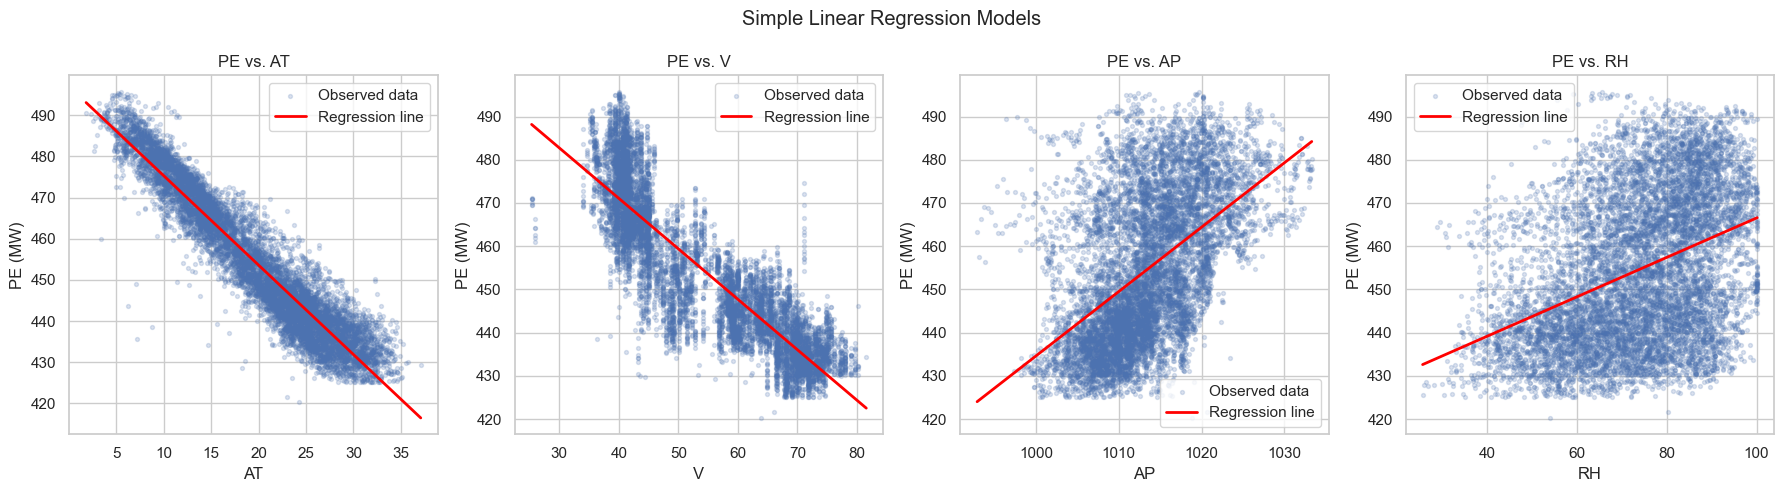

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for predictor, ax in zip(predictors, axes.flat):
    model = models[predictor]

    x_grid = pd.DataFrame({
        predictor: np.linspace(
            df[predictor].min(),
            df[predictor].max(),
            200
        )
    })

    y_pred = model.predict(x_grid)

    ax.scatter(
        df[predictor], df["PE"],
        s=8, alpha=0.2, label="Observed data"
    )

    ax.plot(
        x_grid[predictor], y_pred,
        color="red", linewidth=2, label="Regression line"
    )

    ax.set(
        xlabel=predictor,
        ylabel="PE (MW)",
        title=f"PE vs. {predictor}"
    )
    ax.legend()

fig.suptitle("Simple Linear Regression Models")
fig.tight_layout()
plt.show()

I would not remove any observations from the four regression tasks. Although some points lie far from the fitted lines, each simple regression uses only one predictor. Large residuals may therefore reflect the effects of omitted variables or nonlinear relationships rather than errors in the data. An observation that appears unusual in one simple regression may be better explained when other predictors are included.
Without evidence of measurement or recording errors, I would retain all observations and investigate these potential outliers further using other models.


<a id="multiple"></a>
## 1(d). Multiple linear regression
Fit $PE=\beta_0+\beta_{AT}AT+\beta_VV+\beta_{AP}AP+\beta_{RH}RH+\epsilon$.

In [6]:
import statsmodels.formula.api as smf
import pandas as pd

multiple_model = smf.ols(
    formula="PE ~ AT + V + AP + RH",
    data=df
).fit()

print(multiple_model.summary())

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.929
Model:                            OLS   Adj. R-squared:                  0.929
Method:                 Least Squares   F-statistic:                 3.114e+04
Date:                Sat, 26 Sep 2026   Prob (F-statistic):               0.00
Time:                        14:28:57   Log-Likelihood:                -28088.
No. Observations:                9568   AIC:                         5.619e+04
Df Residuals:                    9563   BIC:                         5.622e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    454.6093      9.749     46.634      0.0

A multiple linear regression model was fitted using AT, V, AP, and RH to predict PE. The model has an R-squared of approximately 0.9287, explaining about 92.87% of the observed variation in electrical power output.
Holding the other predictors constant, AT, V, and RH have negative associations with PE, while AP has a positive association. Each coefficient represents the expected change in PE associated with a one-unit increase in that predictor, with the remaining predictors held fixed.

All four predictors have p-values below 0.05. Therefore, we reject the null hypothesis $H_0:\beta_j=0$ for AT, V, AP, and RH. Each predictor has a statistically significant association with PE after adjusting for the other predictors.

## 1(e). Compare simple and multiple regression coefficients

,Simple coefficient,Multiple coefficient
Predictor,,
AT,-2.1713,-1.9775
V,-1.1681,-0.2339
AP,1.4899,0.0621
RH,0.4557,-0.1581


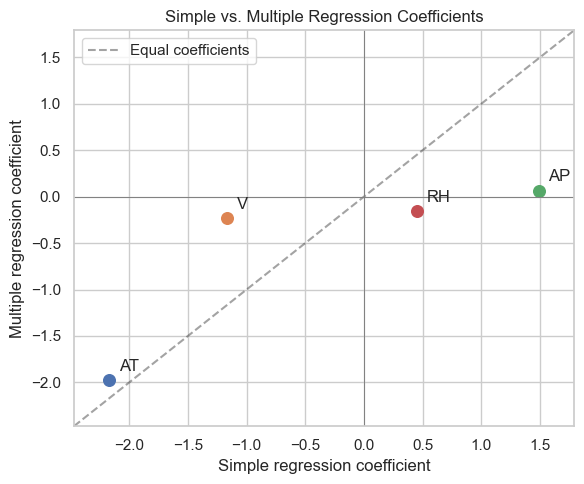

In [7]:
FEATURES = ["AT", "V", "AP", "RH"]

# Fit simple regressions using the full dataset.
simple_models = {
    x: smf.ols(f"PE ~ {x}", data=df).fit()
    for x in FEATURES
}

# Fit the multiple regression using the same dataset.
multiple_model = smf.ols(
    "PE ~ AT + V + AP + RH",
    data=df
).fit()

# Compare slopes in the original units.
coefficient_comparison = pd.DataFrame({
    "Simple coefficient": [
        simple_models[x].params[x] for x in FEATURES
    ],
    "Multiple coefficient": [
        multiple_model.params[x] for x in FEATURES
    ]
}, index=FEATURES)

coefficient_comparison.index.name = "Predictor"
display(coefficient_comparison.round(4))

# Plot one point for each predictor.
fig, ax = plt.subplots(figsize=(6, 5))

for predictor, row in coefficient_comparison.iterrows():
    x = row["Simple coefficient"]
    y = row["Multiple coefficient"]

    ax.scatter(x, y, s=70)
    ax.annotate(
        predictor,
        (x, y),
        xytext=(7, 7),
        textcoords="offset points"
    )

values = coefficient_comparison.to_numpy()
lo = values.min() - 0.3
hi = values.max() + 0.3

ax.plot(
    [lo, hi], [lo, hi],
    "k--", alpha=0.4,
    label="Equal coefficients"
)
ax.axhline(0, color="gray", linewidth=0.7)
ax.axvline(0, color="gray", linewidth=0.7)

ax.set(
    xlabel="Simple regression coefficient",
    ylabel="Multiple regression coefficient",
    title="Simple vs. Multiple Regression Coefficients",
    xlim=(lo, hi),
    ylim=(lo, hi)
)

ax.legend()
plt.tight_layout()
plt.show()

**Interpretation.** AT stays strongly negative, but the magnitude of V's slope shrinks substantially after adjustment. AP's positive association also becomes much smaller. RH reverses from positive in its simple regression to negative in the multiple regression. These changes are consistent with correlated predictors: a marginal slope blends the predictor's association with the information it shares with the omitted variables. All four remain statistically significant, but their conditional interpretation differs from 1 (c).

<a id="nonlinear"></a>
## 1(f). Cubic regressions and evidence of nonlinearity
For each predictor, fit $PE=\beta_0+\beta_1X+\beta_2X^2+\beta_3X^3+\epsilon$.
For numerical stability, use $z=(X-\bar X)/s_X$ and powers of z. This spans exactly the same cubic model as powers of X. The joint nested F-test of $H_0:\beta_2=\beta_3=0$ tests whether the nonlinear terms improve on a straight line. Individual term tests and the joint test answer different questions.

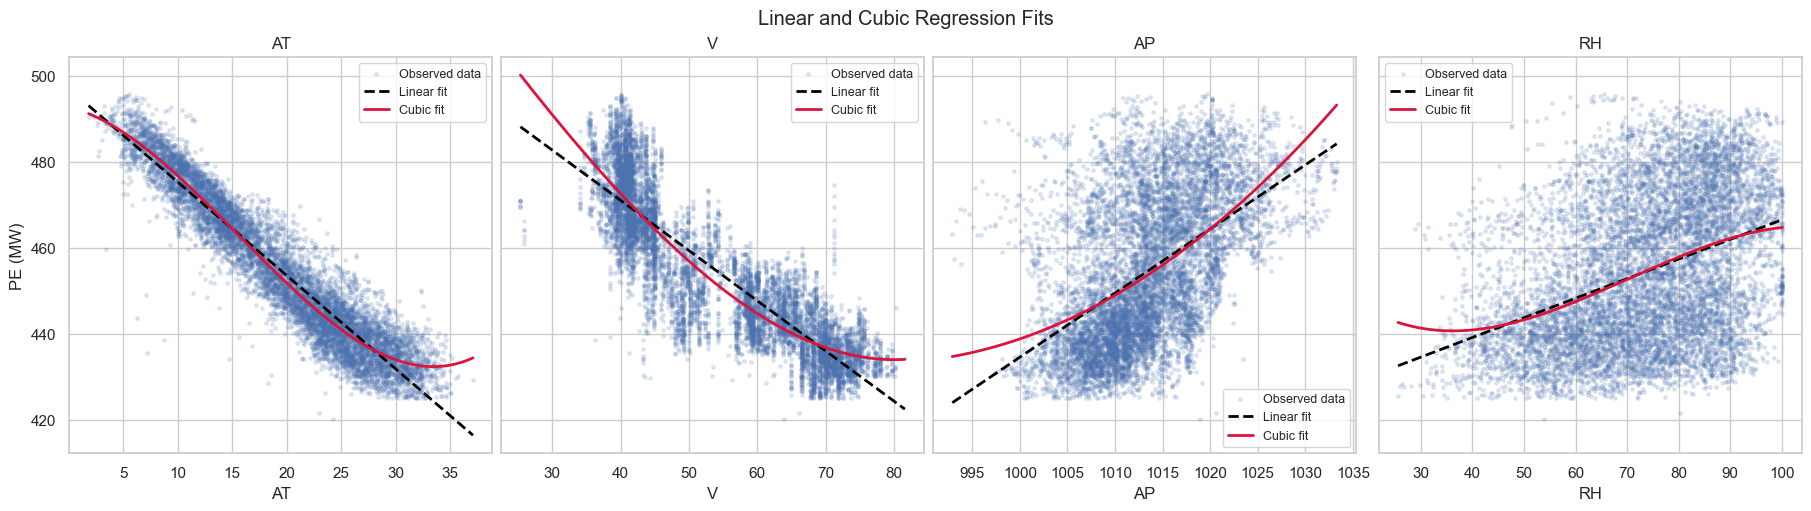

,Joint p-value,Evidence of nonlinearity
Predictor,,
AT,3.478e-285,True
V,7.040e-165,True
AP,3.647e-19,True
RH,3.800e-05,True


In [8]:

ALPHA = 0.05

coefficient_rows = []
nonlinear_rows = []

fig, axes = plt.subplots(
    1, 4,
    figsize=(18, 5),
    sharey=True,
    constrained_layout=True
)

for predictor, ax in zip(FEATURES, axes.flat):
    # Fit models using the predictor's original units.
    linear = smf.ols(
        f"PE ~ {predictor}",
        data=df
    ).fit()

    cubic = smf.ols(
        f"PE ~ {predictor} + I({predictor} ** 2) "
        f"+ I({predictor} ** 3)",
        data=df
    ).fit()

    terms = {
        "Beta 0 (Intercept)": "Intercept",
        "Beta 1 (X)": predictor,
        "Beta 2 (X^2)": f"I({predictor} ** 2)",
        "Beta 3 (X^3)": f"I({predictor} ** 3)"
    }

    for label, term in terms.items():
        p_value = cubic.pvalues[term]

        coefficient_rows.append({
            "Predictor": predictor,
            "Term": label,
            "Coefficient": cubic.params[term],
            "P-value": p_value,
            "Significant (p < 0.05)": p_value < ALPHA
        })

    # Test H0: beta_2 = beta_3 = 0.
    _, p_joint, _ = cubic.compare_f_test(linear)

    nonlinear_rows.append({
        "Predictor": predictor,
        "Joint p-value": p_joint,
        "Evidence of nonlinearity": p_joint < ALPHA
    })

    # Plot observations and fitted curves.
    grid = pd.DataFrame({
        predictor: np.linspace(
            df[predictor].min(),
            df[predictor].max(),
            300
        )
    })

    ax.scatter(
        df[predictor], df["PE"],
        s=6, alpha=0.15,
        label="Observed data"
    )
    ax.plot(
        grid[predictor], linear.predict(grid),
        color="black", linestyle="--",
        linewidth=2, label="Linear fit"
    )
    ax.plot(
        grid[predictor], cubic.predict(grid),
        color="crimson",
        linewidth=2, label="Cubic fit"
    )

    ax.set(title=predictor, xlabel=predictor)
    ax.legend(fontsize=9)

axes[0].set_ylabel("PE (MW)")
fig.suptitle("Linear and Cubic Regression Fits")
plt.show()

# Display coefficient estimates and individual significance tests.
coefficient_results = (
    pd.DataFrame(coefficient_rows)
    .set_index(["Predictor", "Term"])
)

display(
    coefficient_results.style.format({
        "Coefficient": "{:.6g}",
        "P-value": "{:.3e}"
    })
)

# Display joint tests for nonlinearity.
nonlinear_results = (
    pd.DataFrame(nonlinear_rows)
    .set_index("Predictor")
)

display(
    nonlinear_results.style.format({
        "Joint p-value": "{:.3e}"
    })
)

There is statistically significant evidence of nonlinear associations between PE and all four predictors.

- **AT:** Both the quadratic and cubic terms are statistically significant.
- **V:** The quadratic term is not individually significant ($p = 0.7685$), but the cubic term is significant ($p = 0.01373$), providing evidence of nonlinearity.
- **AP:** Both the quadratic and cubic terms are statistically significant.
- **RH:** Both the quadratic and cubic terms are statistically significant.

The joint tests are significant for all four predictors at the 0.05 level, indicating that the nonlinear terms collectively improve the fit compared with a straight-line model.

## 1(g). All pairwise interactions
Fit four main effects and the six distinct two-predictor products, without squares:
$PE=\beta_0+\sum_j\beta_jX_j+\sum_{j<k}\beta_{jk}X_jX_k+\epsilon$.
An interaction means that the slope for one predictor depends on the value of another predictor. We report individual t-tests and a joint F-test against the additive model.

In [9]:
# Fit all main effects and pairwise interactions.
interaction_model = smf.ols(
    "PE ~ (AT + V + AP + RH) ** 2",
    data=df
).fit()

# Summarize every model term.
results = pd.DataFrame({
    "Coefficient": interaction_model.params,
    "P-value": interaction_model.pvalues,
    "Significant (p < 0.05)": interaction_model.pvalues < 0.05
})

results.index.name = "Term"

display(
    results.style.format({
        "Coefficient": "{:.6g}",
        "P-value": "{:.3e}"
    })
)

,Coefficient,P-value,Significant (p < 0.05)
Term,,,
Intercept,685.782,3.232e-18,True
AT,-4.34701,6.702e-02,False
V,-7.67486,1.371e-08,True
AP,-0.152355,4.736e-02,True
RH,1.57091,4.225e-02,True
AT:V,0.0209709,3.333e-117,True
AT:AP,0.00175905,4.521e-01,False
AT:RH,-0.00523035,1.217e-10,True
V:AP,0.00681235,2.877e-07,True


The interactions **AT × V, AT × RH, V × AP, and AP × RH** are significant at the 0.05 level, indicating that some predictors’ associations with PE depend on other predictors’ values. **AT × AP and V × RH** are not significant.

<a id="prediction"></a>
## 1(h). Prediction with a fixed 70/30 split
Compare an additive model with a full second-degree model containing four main effects, four squares, and six pairwise interactions. Select terms using **training data only**.

Backward elimination removes the eligible term with the largest p-value above 0.05, refitting after each removal. **Strong hierarchy** is preserved: a main effect cannot be removed while a retained square or interaction contains that predictor. Such a protected main effect may legitimately have p > 0.05. Selection p-values are exploratory, not valid post-selection confirmatory inference. Centering/scaling is learned from the training split only.

In [10]:

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from itertools import combinations


FEATURES = ["AT", "V", "AP", "RH"]
ALPHA = 0.05

# Split the original data without scaling or centering.
train, test = train_test_split(
    df,
    test_size=0.30,
    random_state=42
)


def fit_terms(terms):
    formula = "PE ~ " + (" + ".join(terms) if terms else "1")
    return smf.ols(formula, data=train).fit()


def show_coefficients(model):
    results = pd.DataFrame({
        "Coefficient": model.params,
        "P-value": model.pvalues,
        "Significant (p < 0.05)": model.pvalues < ALPHA
    })
    results.index.name = "Term"

    display(
        results.style.format({
            "Coefficient": "{:.6g}",
            "P-value": "{:.3e}"
        })
    )


# Model 1: Additive linear regression.
linear_model = fit_terms(FEATURES)

print("Model 1: Additive Linear Regression")
show_coefficients(linear_model)


# Model 2: All main effects, squares, and pairwise interactions.
squares = [f"I({x} ** 2)" for x in FEATURES]

interactions = [
    f"{a}:{b}"
    for a, b in combinations(FEATURES, 2)
]

full_terms = FEATURES + squares + interactions
full_model = fit_terms(full_terms)

print("\nModel 2: Full Quadratic Regression")
show_coefficients(full_model)


# Define the main effects required by each higher-order term.
parents = {
    f"I({x} ** 2)": {x}
    for x in FEATURES
}

parents.update({
    f"{a}:{b}": {a, b}
    for a, b in combinations(FEATURES, 2)
})

selected_terms = full_terms.copy()
removed = []

# Backward elimination using training data only.
while True:
    selected_model = fit_terms(selected_terms)

    # Protect main effects required by retained squares or interactions.
    protected = set()
    for term in selected_terms:
        protected.update(parents.get(term, set()))

    eligible = [
        term for term in selected_terms
        if term not in protected
    ]

    if not eligible:
        break

    p_values = selected_model.pvalues[eligible]
    worst_term = p_values.idxmax()
    worst_p = p_values[worst_term]

    if worst_p <= ALPHA:
        break

    removed.append({
        "Step": len(removed) + 1,
        "Removed term": worst_term,
        "P-value at removal": worst_p
    })

    selected_terms.remove(worst_term)


print("\nRemoved Terms")

if removed:
    removed_results = (
        pd.DataFrame(removed)
        .set_index("Step")
    )

    display(
        removed_results.style.format({
            "P-value at removal": "{:.3e}"
        })
    )
else:
    print("No terms were removed.")


# Model 3: Quadratic regression after backward elimination.
print("\nModel 3: Selected Quadratic Regression")
show_coefficients(selected_model)


# Evaluate all three models on the same training and test sets.
models_h = {
    "Model 1: Additive linear": linear_model,
    "Model 2: Full quadratic": full_model,
    "Model 3: Selected quadratic": selected_model
}

mse_rows = []

for name, model in models_h.items():
    mse_rows.append({
        "Model": name,
        "Train MSE": mean_squared_error(
            train["PE"],
            model.predict(train)
        ),
        "Test MSE": mean_squared_error(
            test["PE"],
            model.predict(test)
        )
    })

mse_results = (
    pd.DataFrame(mse_rows)
    .set_index("Model")
)

print("\nModel Comparison — MSE (MW²)")
display(mse_results.style.format("{:.3f}"))

Model 1: Additive Linear Regression


,Coefficient,P-value,Significant (p < 0.05)
Term,,,
Intercept,467.841,0.000e+00,True
AT,-2.00442,0.000e+00,True
V,-0.227127,3.606e-145,True
AP,0.049301,1.022e-05,True
RH,-0.159973,2.738e-213,True



Model 2: Full Quadratic Regression


,Coefficient,P-value,Significant (p < 0.05)
Term,,,
Intercept,-7664.98,8.518e-08,True
AT,-7.28854,4.461e-02,True
V,-1.95896,2.672e-01,False
AP,15.9308,9.535e-09,True
RH,3.91213,1.429e-04,True
I(AT ** 2),0.0184947,5.017e-07,True
I(V ** 2),-0.000364945,6.998e-01,False
I(AP ** 2),-0.00775793,8.522e-09,True
I(RH ** 2),-0.00189544,1.395e-09,True



Removed Terms


,Removed term,P-value at removal
Step,,
1,V:RH,8.674e-01
2,I(V ** 2),6.077e-01
3,V:AP,3.578e-01



Model 3: Selected Quadratic Regression


,Coefficient,P-value,Significant (p < 0.05)
Term,,,
Intercept,-7568.52,1.026e-07,True
AT,-9.6925,2.345e-05,True
V,-0.460354,4.323e-46,True
AP,15.7203,1.173e-08,True
RH,3.72036,1.355e-04,True
I(AT ** 2),0.0195345,5.854e-16,True
I(AP ** 2),-0.00764403,1.073e-08,True
I(RH ** 2),-0.00194027,2.022e-12,True
AT:V,0.00824627,1.548e-08,True



Model Comparison — MSE (MW²)


,Train MSE,Test MSE
Model,,
Model 1: Additive linear,20.581,21.240
Model 2: Full quadratic,17.888,18.647
Model 3: Selected quadratic,17.891,18.660


<a id="knn"></a>
## 1(i). K-nearest-neighbor regression


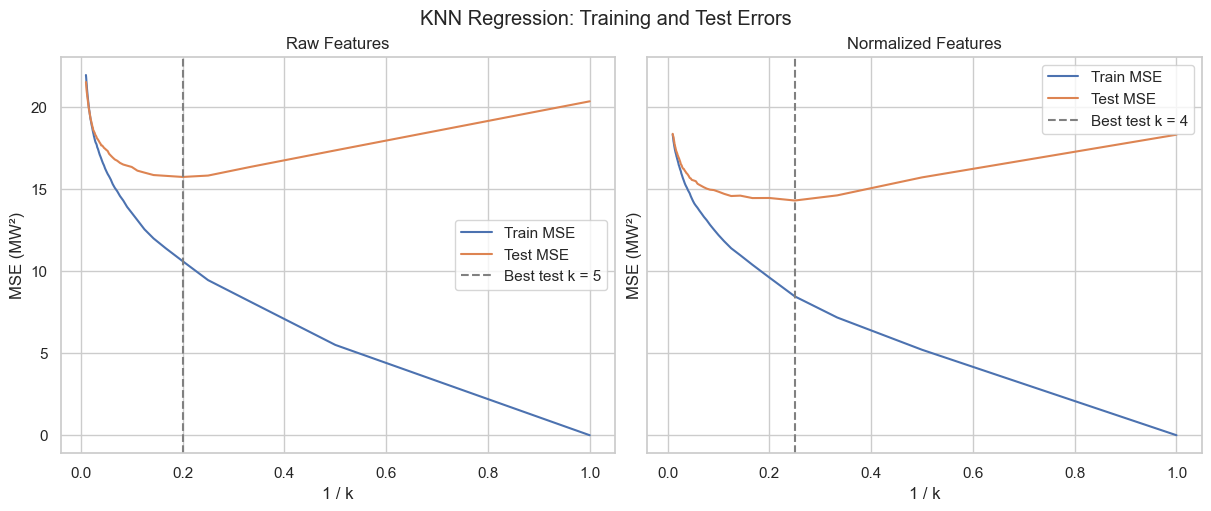

,Best k,Train MSE,Test MSE
Features,,,
Raw,5,10.601,15.727
Normalized,4,8.454,14.291


In [11]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import MinMaxScaler

FEATURES = ["AT", "V", "AP", "RH"]
K_VALUES = range(1, 101)

X_train = train[FEATURES]
X_test = test[FEATURES]
y_train = train["PE"]
y_test = test["PE"]

# Fit the scaler on training data only.
scaler = MinMaxScaler()
X_train_normalized = scaler.fit_transform(X_train)
X_test_normalized = scaler.transform(X_test)

feature_sets = {
    "Raw": (X_train, X_test),
    "Normalized": (X_train_normalized, X_test_normalized)
}

knn_results = {}
best_rows = []

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5),
    sharey=True,
    constrained_layout=True
)

for (name, (Xtr, Xte)), ax in zip(feature_sets.items(), axes):
    rows = []

    for k in K_VALUES:
        model = KNeighborsRegressor(
            n_neighbors=k,
            weights="uniform",
            metric="euclidean",
            algorithm="brute",
            n_jobs=-1
        )
        model.fit(Xtr, y_train)

        rows.append({
            "k": k,
            "Train MSE": mean_squared_error(
                y_train, model.predict(Xtr)
            ),
            "Test MSE": mean_squared_error(
                y_test, model.predict(Xte)
            )
        })

    results = pd.DataFrame(rows)
    knn_results[name] = results

    # Identify the minimum on the test-error curve.
    best = results.loc[results["Test MSE"].idxmin()]
    best_k = int(best["k"])

    best_rows.append({
        "Features": name,
        "Best k": best_k,
        "Train MSE": best["Train MSE"],
        "Test MSE": best["Test MSE"]
    })

    plot_data = results.assign(
        inverse_k=1 / results["k"]
    ).sort_values("inverse_k")

    ax.plot(
        plot_data["inverse_k"],
        plot_data["Train MSE"],
        label="Train MSE"
    )
    ax.plot(
        plot_data["inverse_k"],
        plot_data["Test MSE"],
        label="Test MSE"
    )
    ax.axvline(
        1 / best_k,
        color="gray",
        linestyle="--",
        label=f"Best test k = {best_k}"
    )

    ax.set(
        title=f"{name} Features",
        xlabel="1 / k",
        ylabel="MSE (MW²)"
    )
    ax.legend()

fig.suptitle("KNN Regression: Training and Test Errors")
plt.show()

best_knn_results = (
    pd.DataFrame(best_rows)
    .set_index("Features")
)

display(
    best_knn_results.style.format({
        "Best k": "{:.0f}",
        "Train MSE": "{:.3f}",
        "Test MSE": "{:.3f}"
    })
)

## 1(j). Compare KNN and regression

In [12]:
# Find the regression model with the lowest test MSE.
best_regression_name = mse_results["Test MSE"].idxmin()
best_regression = mse_results.loc[best_regression_name]

# Compare the best regression with raw and normalized KNN.
comparison_rows = [{
    "Model": best_regression_name,
    "Train MSE": best_regression["Train MSE"],
    "Test MSE": best_regression["Test MSE"]
}]

for features, row in best_knn_results.iterrows():
    comparison_rows.append({
        "Model": f"{features} KNN (k={int(row['Best k'])})",
        "Train MSE": row["Train MSE"],
        "Test MSE": row["Test MSE"]
    })

comparison = pd.DataFrame(comparison_rows).set_index("Model")
display(comparison.style.format("{:.3f}"))

,Train MSE,Test MSE
Model,,
Model 2: Full quadratic,17.888,18.647
Raw KNN (k=5),10.601,15.727
Normalized KNN (k=4),8.454,14.291


Normalized KNN with **k = 4** performs best, with a test MSE of **14.291**, followed by raw KNN with **k = 5** at **15.727**. Both outperform the full quadratic regression model, which has the lowest test MSE among the regression models at **18.647**.

These results suggest that KNN captures local patterns that the quadratic model does not fully represent. Normalization further improves KNN performance by adjusting the relative contribution of each feature to the distance calculation.

<a id="islr"></a>
## 2. ISLR §2.4, Exercise 1
| Part | Scenario | Answer | Explanation |
|---|---|---|---|
| (a) | The sample size $n$ is extremely large, and the number of predictors $p$ is small. | Better | A large sample allows a flexible method to capture complex patterns with less risk of overfitting. |
| (b) | The number of predictors $p$ is extremely large, and the number of observations $n$ is small. | Worse | With many predictors and few observations, a flexible method is more likely to overfit, leading to high variance and poor test performance. |
| (c) | The relationship between the predictors and response is highly nonlinear. | Better | A flexible method can capture nonlinear patterns more accurately, reducing bias. |
| (d) | The error variance $\sigma^2 = \operatorname{Var}(\epsilon)$ is extremely high. | Worse | A flexible method is more likely to fit noise, increasing variance without reducing the irreducible error. |

## 3. ISLR §2.4, Exercise 7

### (a) Euclidean distances

The test point is $x_0=(0,0,0)$. The Euclidean distance from observation $i$ to the test point is:

$$
d_i=\sqrt{(X_{i1}-0)^2+(X_{i2}-0)^2+(X_{i3}-0)^2}
$$

For each observation:

$$
d_1=\sqrt{0^2+3^2+0^2}=\sqrt{9}=3
$$

$$
d_2=\sqrt{2^2+0^2+0^2}=\sqrt{4}=2
$$

$$
d_3=\sqrt{0^2+1^2+3^2}=\sqrt{10}\approx3.162
$$

$$
d_4=\sqrt{0^2+1^2+2^2}=\sqrt{5}\approx2.236
$$

$$
d_5=\sqrt{(-1)^2+0^2+1^2}=\sqrt{2}\approx1.414
$$

$$
d_6=\sqrt{1^2+1^2+1^2}=\sqrt{3}\approx1.732
$$

Sorting the observations from nearest to farthest:

| Rank | Observation | Distance | Class |
|---|---|---|---|
| 1 | 5 | $\sqrt{2}\approx1.414$ | Green |
| 2 | 6 | $\sqrt{3}\approx1.732$ | Red |
| 3 | 2 | $2$ | Red |
| 4 | 4 | $\sqrt{5}\approx2.236$ | Green |
| 5 | 1 | $3$ | Red |
| 6 | 3 | $\sqrt{10}\approx3.162$ | Red |

### (b) Prediction with $K=1$

The nearest neighbor is observation **5**, whose class is **Green**. Therefore:

$$
\hat Y=\text{Green}
$$

### (c) Prediction with $K=3$

The three nearest neighbors are observations **5, 6, and 2**, with classes **Green, Red, and Red**, respectively.

The votes are:

- **Red:** 2 votes
- **Green:** 1 vote

The estimated class probabilities are:

$$
\hat P(Y=\text{Red}\mid x_0)=\frac{2}{3},
\qquad
\hat P(Y=\text{Green}\mid x_0)=\frac{1}{3}
$$

Red receives the majority of votes. Therefore:

$$
\hat Y=\text{Red}
$$

### (d) Choice of $K$ for a highly nonlinear boundary

We would generally expect a **smaller $K$** to perform better because it produces a more flexible decision boundary that can capture local, nonlinear patterns.

A larger $K$ averages over a broader neighborhood, creating a smoother boundary that may underfit the nonlinear structure.